In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
%pip -q install -U diffusers accelerate scikit-learn scipy

In [3]:
import math, time, random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.datasets import make_swiss_roll, make_moons, make_circles, make_blobs
from scipy.spatial import cKDTree

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device)

device: cuda



## A. 2D Toy Dataset Generation and Visualization

Generate and visualize 20 different 2D toy distributions for diffusion model experiments.

### Dataset Generation and Visualization

Set up the required libraries and execution environment, and generate various 2D datasets. Normalize the coordinate scales of each dataset and visualize the distributions using scatter plots.


In [4]:
def toy_data(name, N=6000, seed=42):
    rng = np.random.default_rng(seed)
    if name == 'swiss_roll':
        X,_ = make_swiss_roll(N, noise=.25, random_state=seed); X=X[:,[0,2]]
    elif name == 'moons':
        X,_ = make_moons(N, noise=.06, random_state=seed)
    elif name == 'circles':
        X,_ = make_circles(N, noise=.035, factor=.45, random_state=seed)
    elif name == 'eight_gaussians':
        k=rng.integers(0,8,N); a=2*np.pi*k/8
        X=np.stack([3*np.cos(a),3*np.sin(a)],1)+rng.normal(0,.16,(N,2))
    elif name == 'four_gaussians':
        centers=np.array([[-2,-2],[-2,2],[2,-2],[2,2]])
        X=centers[rng.integers(0,4,N)]+rng.normal(0,.28,(N,2))
    elif name == 'two_gaussians':
        X=np.array([[-2,0],[2,0]])[rng.integers(0,2,N)]+rng.normal(0,.3,(N,2))
    elif name == 'rings':
        k=rng.integers(0,4,N); a=rng.uniform(0,2*np.pi,N)
        r=np.array([.5,1.2,1.9,2.6])[k]+rng.normal(0,.055,N)
        X=np.stack([r*np.cos(a),r*np.sin(a)],1)
    elif name == 'spirals':
        k=rng.integers(0,2,N); t=rng.uniform(.15,1,N)
        a=t*3.5*np.pi+k*np.pi; r=3*t
        X=np.stack([r*np.cos(a),r*np.sin(a)],1)+rng.normal(0,.09,(N,2))
    elif name == 'checkerboard':
        x=rng.uniform(-2,2,N); y=rng.uniform(0,1,N)-2*rng.integers(0,2,N)
        y=y+(np.floor(x).astype(int)%2); X=np.stack([x,y],1)
    elif name == 'pinwheel':
        k=rng.integers(0,5,N); r=rng.normal(2,.3,N)
        a=2*np.pi*k/5+.7*r+rng.normal(0,.06,N)
        X=np.stack([r*np.cos(a),r*np.sin(a)],1)
    elif name == 'grid':
        centers=np.array([(i,j) for i in [-2,0,2] for j in [-2,0,2]])
        X=centers[rng.integers(0,9,N)]+rng.normal(0,.14,(N,2))
    elif name == 'line':
        x=rng.uniform(-3,3,N); X=np.stack([x, .65*x + rng.normal(0,.15,N)],1)
    elif name == 'blobs':
        X,_=make_blobs(n_samples=N, centers=5, cluster_std=.55, random_state=seed)
    elif name == 's_curve':
        t=rng.uniform(-1.5*np.pi,1.5*np.pi,N)
        X=np.stack([t,2*np.sin(t)],1)+rng.normal(0,.12,(N,2))
    elif name == 'cross':
        a=rng.uniform(-3,3,N); b=rng.normal(0,.13,N)
        X=np.stack([a,b],1); mask=rng.random(N)<.5; X[mask]=X[mask][:,::-1]
    elif name == 'diamond':
        a=rng.uniform(-1,1,(N,2)); a=a/(np.abs(a).sum(1,keepdims=True)+1e-6)
        radius=np.sqrt(rng.uniform(0,1,(N,1))); X=3*a*radius
    elif name == 'uniform_square':
        X=rng.uniform(-2,2,(N,2))
    elif name == 'uniform_disk':
        a=rng.uniform(0,2*np.pi,N); r=2.5*np.sqrt(rng.random(N))
        X=np.stack([r*np.cos(a),r*np.sin(a)],1)
    elif name == 'star':
        a=rng.uniform(0,2*np.pi,N); r=1.8+.8*np.cos(5*a)+rng.normal(0,.06,N)
        X=np.stack([r*np.cos(a),r*np.sin(a)],1)
    elif name == 'heart':
        t=rng.uniform(0,2*np.pi,N)
        X=np.stack([16*np.sin(t)**3,
            13*np.cos(t)-5*np.cos(2*t)-2*np.cos(3*t)-np.cos(4*t)],1)
        X+=rng.normal(0,.7,(N,2))
    else: raise ValueError(name)
    X=X.astype('float32'); X=(X-X.mean(0))/(X.std(0)+1e-6)*1.6
    return X

device: cuda


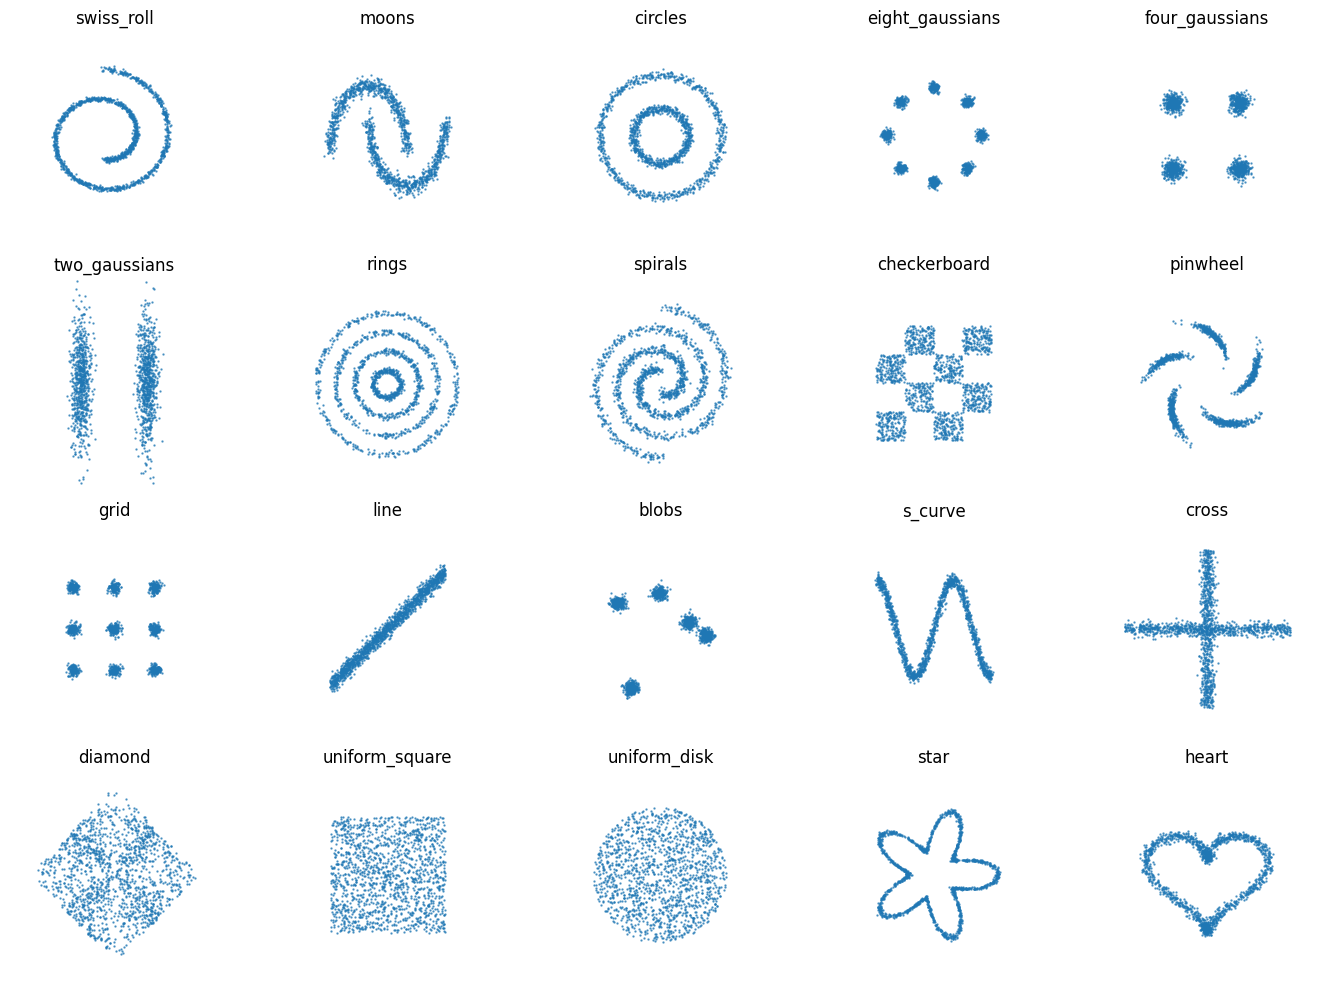

In [2]:
DATASETS = ['swiss_roll','moons','circles','eight_gaussians','four_gaussians',
            'two_gaussians','rings','spirals','checkerboard','pinwheel','grid','line',
            'blobs','s_curve','cross','diamond','uniform_square','uniform_disk','star','heart']
fig,axs=plt.subplots(4,5,figsize=(14,10))
for ax,name in zip(axs.flat,DATASETS):
    X=toy_data(name,1500); ax.scatter(X[:,0],X[:,1],s=.5,alpha=.7)
    ax.set(title=name,xlim=(-5,5),ylim=(-5,5),aspect='equal'); ax.axis('off')
plt.tight_layout(); plt.show()


## B. Forward Diffusion & Time-conditioned MLP

This section introduces the forward diffusion process and defines a time-conditioned neural network for predicting the added Gaussian noise.

### 1. Forward Diffusion: Adding Gaussian Noise

Select a 2D toy dataset and define a noise schedule with 1,000 timesteps. Apply the forward diffusion process to gradually add Gaussian noise to the original data, and visualize how the data distribution changes over time.

**Forward Diffusion Equation:**

$$
x_t = \sqrt{\bar{\alpha}_t}x_0
+ \sqrt{1-\bar{\alpha}_t}\epsilon,
\qquad \epsilon \sim \mathcal{N}(0,I)
$$

where

- $x_0$: Original data sample
- $x_t$: Noisy data sample at timestep $t$
- $\alpha_t = 1-\beta_t$: Signal retention factor at timestep $t$
- $\bar{\alpha}_t = \prod_{s=1}^{t}\alpha_s$: Cumulative signal retention factor
- $\epsilon$: Standard Gaussian noise

As $t$ increases, the contribution of the original data decreases while the contribution of Gaussian noise increases.


In [ ]:
DATASET = 'spirals'
N_DATA = 12000
X = torch.tensor(toy_data(DATASET, N_DATA), device=device)
T = 1000
beta = torch.linspace(1e-4, 0.02, T, device=device)
alpha = 1 - beta
abar = torch.cumprod(alpha, dim=0)

def q_sample(x0,t,noise=None):
    noise = torch.randn_like(x0) if noise is None else noise
    a = abar[t].reshape(-1,1)
    return a.sqrt()*x0 + (1-a).sqrt()*noise

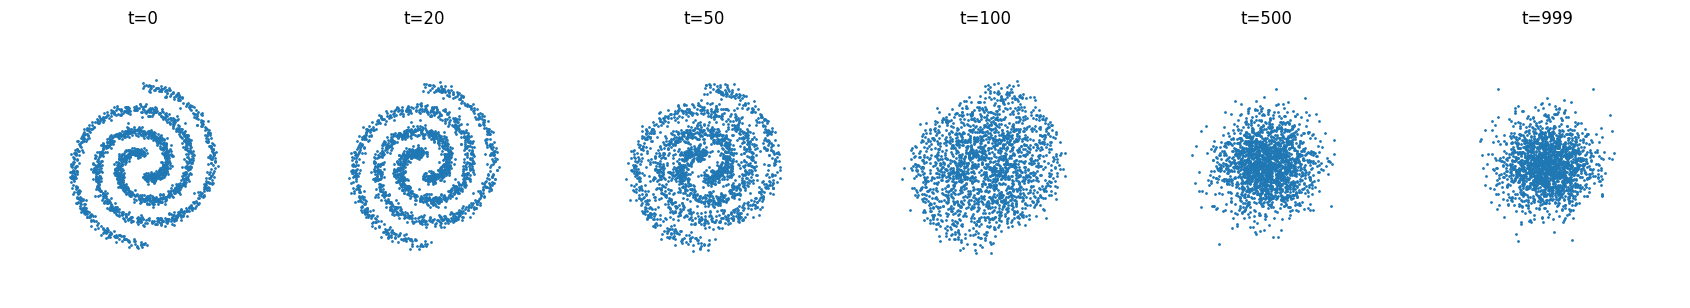

In [3]:
x0=X[:2000]; eps=torch.randn_like(x0)
fig,axes=plt.subplots(1,6,figsize=(17,3))
for ax,t in zip(axes,[0,20,50,100,500,999]):
    xt=q_sample(x0,torch.full((len(x0),),t,device=device),eps)
    v=xt.cpu().numpy(); ax.scatter(v[:,0],v[:,1],s=1)
    ax.set(title=f't={t}',xlim=(-6,6),ylim=(-6,6),aspect='equal'); ax.axis('off')
plt.tight_layout();plt.show()


### 2. Noise Prediction Network Architecture

Define a **Time-conditioned Residual MLP** that predicts the Gaussian noise added to 2D data samples.

The network takes a noisy sample $x_t \in \mathbb{R}^2$ and its timestep $t$ as inputs, and predicts the corresponding noise vector $\epsilon_\theta(x_t,t)$.

The architecture consists of four components:

1. **Time Embedding (64 dimensions):** Encodes the timestep using sinusoidal functions to provide information about the noise level.

2. **Input Projection (66 → 256):** Concatenates the 2D sample and 64-dimensional time embedding, then projects them into a 256-dimensional hidden representation.

3. **Residual MLP Blocks (4 blocks):** Processes the hidden representation using four residual blocks, each containing two linear layers, SiLU activations, and a skip connection.

4. **Output Projection (256 → 2):** Produces a 2D vector representing the predicted Gaussian noise.

**Architecture Overview:**

$$
(x_t,t)
\xrightarrow{\text{Time Embedding \& Concatenation}}
\mathbb{R}^{66}
\xrightarrow{\text{Linear}}
\mathbb{R}^{256}
\xrightarrow{\text{4 Residual Blocks}}
\mathbb{R}^{256}
\xrightarrow{\text{Linear}}
\hat{\epsilon}\in\mathbb{R}^{2}
$$


In [6]:
class TimeEmbedding(nn.Module):
    def __init__(self, dim=64):
        super().__init__(); self.dim=dim
    def forward(self,t):
        freq=torch.exp(torch.arange(self.dim//2,device=t.device)*(-math.log(10000)/(self.dim//2-1)))
        arg=t.float()[:,None]*freq[None,:]
        return torch.cat([arg.sin(),arg.cos()],dim=-1)

class ResBlock(nn.Module):
    def __init__(self,width):
        super().__init__()
        self.net=nn.Sequential(nn.Linear(width,width),nn.SiLU(),nn.Linear(width,width))
    def forward(self,x): return F.silu(x+self.net(x))

class NoisePredictor(nn.Module):
    def __init__(self,width=256,blocks=4):
        super().__init__()
        self.time=TimeEmbedding(64)
        self.start=nn.Linear(2+64,width)
        self.blocks=nn.Sequential(*[ResBlock(width) for _ in range(blocks)])
        self.end=nn.Linear(width,2)
    def forward(self,x,t):
        h=self.start(torch.cat([x,self.time(t)],1))
        return self.end(self.blocks(F.silu(h)))

model=NoisePredictor().to(device)
opt=torch.optim.Adam(model.parameters(),lr=2e-4)
print('params:',sum(p.numel() for p in model.parameters()))

params: 544002



## C. Training the Noise Prediction Network

Train the noise prediction network using the selected 2D toy dataset.

### Model Training

Add Gaussian noise to data samples at randomly selected timesteps and minimize the Mean Squared Error (MSE) between the predicted and actual noise. Visualize the training loss to monitor the learning process.


Step  2000 | Loss 0.3520
Step  4000 | Loss 0.3489
Step  6000 | Loss 0.3463
Step  8000 | Loss 0.3428
Step 10000 | Loss 0.3398
Step 12000 | Loss 0.3367
Step 14000 | Loss 0.3370
Step 16000 | Loss 0.3359
Step 18000 | Loss 0.3363
Step 20000 | Loss 0.3333


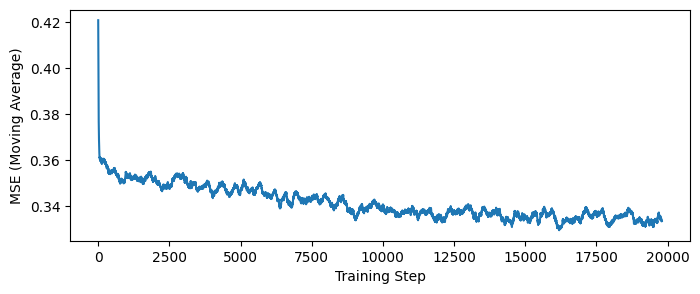

In [11]:
model = NoisePredictor(width=256, blocks=4).to(device)
opt = torch.optim.Adam(model.parameters(), lr=5e-4)

TRAIN_STEPS = 20000
BATCH = 512
losses = []

model.train()

for step in range(TRAIN_STEPS):
    x0 = X[torch.randint(len(X), (BATCH,), device=device)]
    t = torch.randint(0, T, (BATCH,), device=device)
    eps = torch.randn_like(x0)

    xt = q_sample(x0, t, eps)
    loss = F.mse_loss(model(xt, t), eps)

    opt.zero_grad()
    loss.backward()
    opt.step()

    losses.append(loss.item())

    if (step + 1) % 2000 == 0:
        print(f"Step {step+1:5d} | Loss {np.mean(losses[-500:]):.4f}")

model.eval()

plt.figure(figsize=(8, 3))
plt.plot(np.convolve(losses, np.ones(200)/200, mode="valid"))
plt.xlabel("Training Step")
plt.ylabel("MSE (Moving Average)")
plt.show()


## D. Explicit DDPM and DDIM reverse updates

### DDPM and DDIM Reverse Sampling

Implement the reverse sampling processes of DDPM and DDIM using the same trained noise prediction network. Both methods start from Gaussian noise and progressively generate samples resembling the original data distribution. However, they differ in how they remove noise and update the sample at each timestep.

#### 1. DDPM Sampling

$$
x_{t-1} =
\frac{1}{\sqrt{\alpha_t}}
\left(
x_t -
\frac{\beta_t}{\sqrt{1-\bar{\alpha}_t}}
\epsilon_\theta(x_t,t)
\right)
+\sigma_t z
$$

where

- $\epsilon_\theta(x_t,t)$: Noise predicted by the trained network
- $\alpha_t, \beta_t, \bar{\alpha}_t$: Coefficients controlling the noise level at each timestep
- $\sigma_t z$: Stochastic Gaussian noise added during the reverse process, where $z \sim \mathcal{N}(0,I)$ (except at the final step)

DDPM updates the current sample by removing the predicted noise while introducing additional Gaussian noise. Repeating this process gradually produces samples following the learned data distribution through **stochastic sampling**.

#### 2. DDIM Sampling ($\eta=0$)

**Step 1. Estimate the original data**

$$
\hat{x}_0 =
\frac{x_t-\sqrt{1-\bar{\alpha}_t}\epsilon_\theta(x_t,t)}
{\sqrt{\bar{\alpha}_t}}
$$

The original data sample $\hat{x}_0$ is estimated using the current noisy sample $x_t$ and the predicted noise.

**Step 2. Update to the next selected timestep**

$$
x_s =
\sqrt{\bar{\alpha}_s}\hat{x}_0
+
\sqrt{1-\bar{\alpha}_s}\epsilon_\theta(x_t,t)
$$

where

- $\hat{x}_0$: Estimated original data sample
- $s<t$: Next selected sampling timestep
- $\eta=0$: Deterministic sampling without additional Gaussian noise

DDIM uses the estimated original data and predicted noise to compute the sample at a selected earlier timestep. With $\eta=0$, no additional random noise is introduced, resulting in **deterministic sampling**, where the same initial noise produces the same output.

DDIM also supports skipping intermediate timesteps, allowing sample generation with fewer denoising steps.


In [ ]:
@torch.no_grad()
def sample_2d(method='ddim', steps=100, n=3000, seed=42, eta=0.0, keep=True):
    assert method in ('ddpm','ddim')
    if method=='ddpm': steps=T
    g=torch.Generator(device=device).manual_seed(seed)
    xt=torch.randn((n,2),generator=g,device=device)
    times=list(range(T-1,-1,-1)) if method=='ddpm' else torch.linspace(T-1,0,steps).long().tolist()
    trajectory=[(T,xt.detach().cpu())]
    for k,i in enumerate(times):
        t=torch.full((n,),i,device=device,dtype=torch.long)
        eps=model(xt,t)
        a=abar[i]
        if method=='ddpm':
            mu=(xt-beta[i]/(1-a).sqrt()*eps)/alpha[i].sqrt()
            var=beta[i]*(1-abar[i-1])/(1-a) if i>0 else 0.
            xt=mu+var**.5*torch.randn(xt.shape,generator=g,device=device) if i>0 else mu
        else:
            prev=times[k+1] if k+1<len(times) else -1
            ap=abar[prev] if prev>=0 else a.new_tensor(1.)
            x0hat=(xt-(1-a).sqrt()*eps)/a.sqrt()
            sigma=eta*((1-ap)/(1-a)).sqrt()*(1-a/ap).clamp(min=0).sqrt()
            xt=ap.sqrt()*x0hat+(1-ap-sigma**2).clamp(min=0).sqrt()*eps
            if prev>=0 and eta>0:
                xt=xt+sigma*torch.randn(xt.shape,generator=g,device=device)
        if keep and (k+1)%max(1,len(times)//10)==0:
            trajectory.append((i,xt.detach().cpu()))
    return xt.detach().cpu(),trajectory

def cd(x,y):
    x=np.asarray(x);y=np.asarray(y)
    return (cKDTree(x).query(y)[0]**2).mean()+(cKDTree(y).query(x)[0]**2).mean()

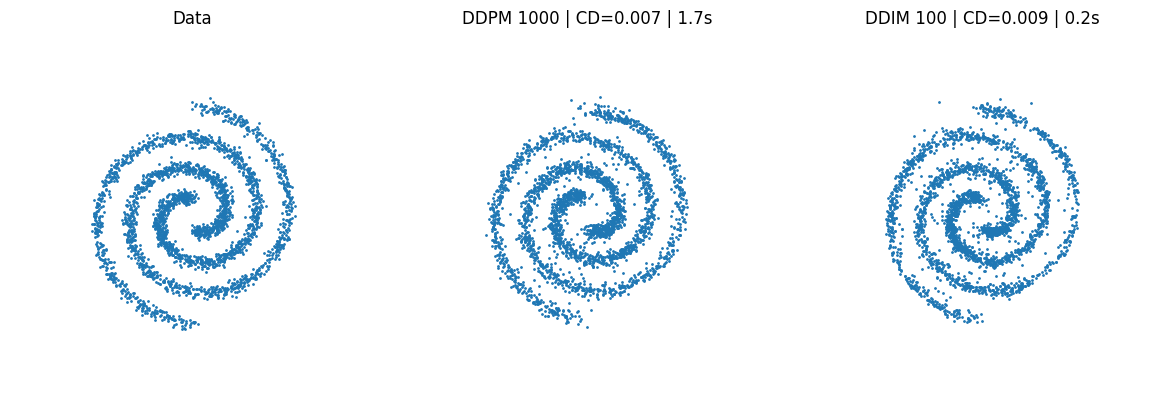

In [12]:
real=X[:3000].cpu().numpy()
fig,ax=plt.subplots(1,3,figsize=(12,4))
ax[0].scatter(*real.T,s=1); ax[0].set_title('Data')
for j,(name,steps) in enumerate([('ddpm',1000),('ddim',100)],1):
    tic=time.perf_counter();out,_=sample_2d(name,steps)
    out=out.numpy();ax[j].scatter(*out.T,s=1)
    ax[j].set_title(f'{name.upper()} {steps} | CD={cd(out,real):.3f} | {time.perf_counter()-tic:.1f}s')
for a in ax: a.set(xlim=(-6,6),ylim=(-6,6),aspect='equal');a.axis('off')
plt.tight_layout();plt.show()


## E. Sampling Steps and Generation Comparison

Compare the generated distributions and reverse sampling trajectories of DDPM and DDIM under different sampling settings.

### Sampling Performance Evaluation

Generate samples using different numbers of DDIM sampling steps. Measure Chamfer Distance and execution time, and visualize the reverse sampling trajectories of DDPM and DDIM.


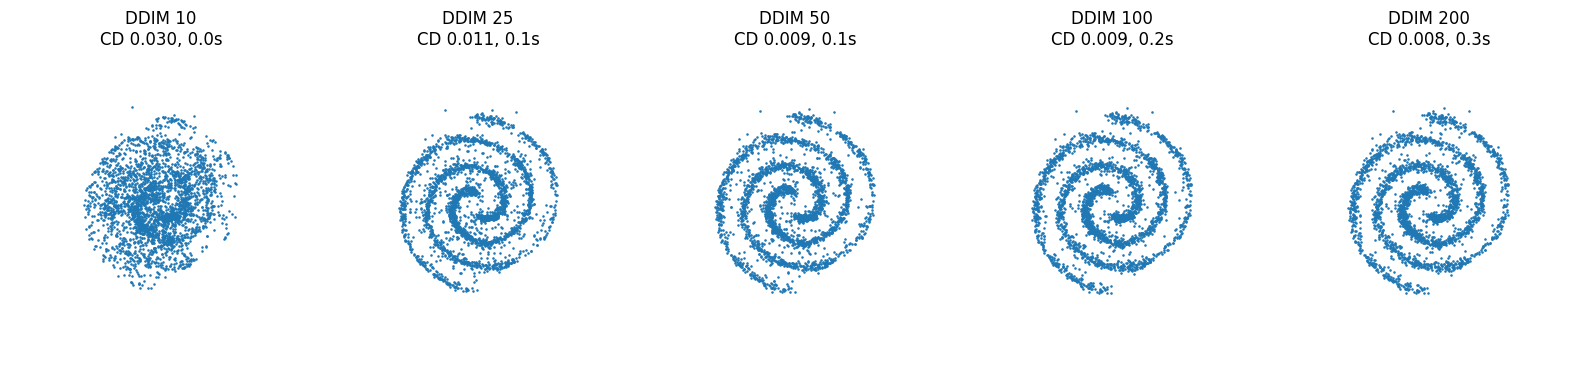

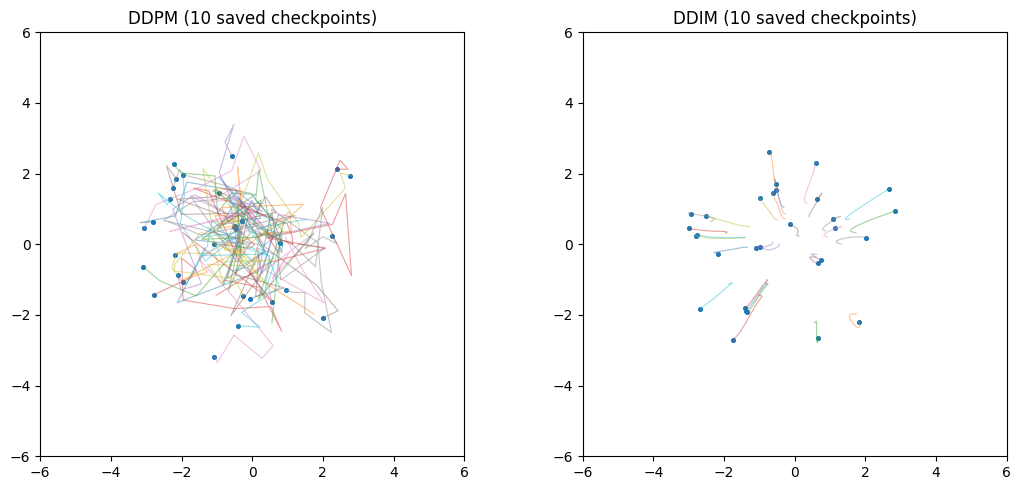

In [13]:
fig,ax=plt.subplots(1,5,figsize=(16,3.5))
for a,s in zip(ax,[10,25,50,100,200]):
    tic=time.perf_counter();out,_=sample_2d('ddim',s)
    a.scatter(*out.numpy().T,s=.7)
    a.set(title=f'DDIM {s}\nCD {cd(out.numpy(),real):.3f}, {time.perf_counter()-tic:.1f}s',
          xlim=(-6,6),ylim=(-6,6),aspect='equal');a.axis('off')
plt.tight_layout();plt.show()

fig,axs=plt.subplots(1,2,figsize=(11,5))
for ax,(method,steps) in zip(axs,[('ddpm',1000),('ddim',100)]):
    _,hist=sample_2d(method,steps,n=30,seed=7)
    paths=torch.stack([p[:30] for _,p in hist]).numpy()
    for j in range(30): ax.plot(paths[:,j,0],paths[:,j,1],alpha=.45,lw=.8)
    ax.scatter(paths[-1,:,0],paths[-1,:,1],s=7)
    ax.set(title=f'{method.upper()} (10 saved checkpoints)',xlim=(-6,6),ylim=(-6,6),aspect='equal')
plt.tight_layout();plt.show()


## F. Generation Across Different Distributions (Optional)

Compare the generation results of DDPM and DDIM across different 2D toy datasets.

### Distribution Comparison

Train separate noise prediction networks for multiple datasets. Visualize the original data distributions alongside DDPM and DDIM samples to compare generation performance across different distribution shapes.


moons: trained 20000 steps
eight_gaussians: trained 20000 steps
rings: trained 20000 steps
cross: trained 20000 steps


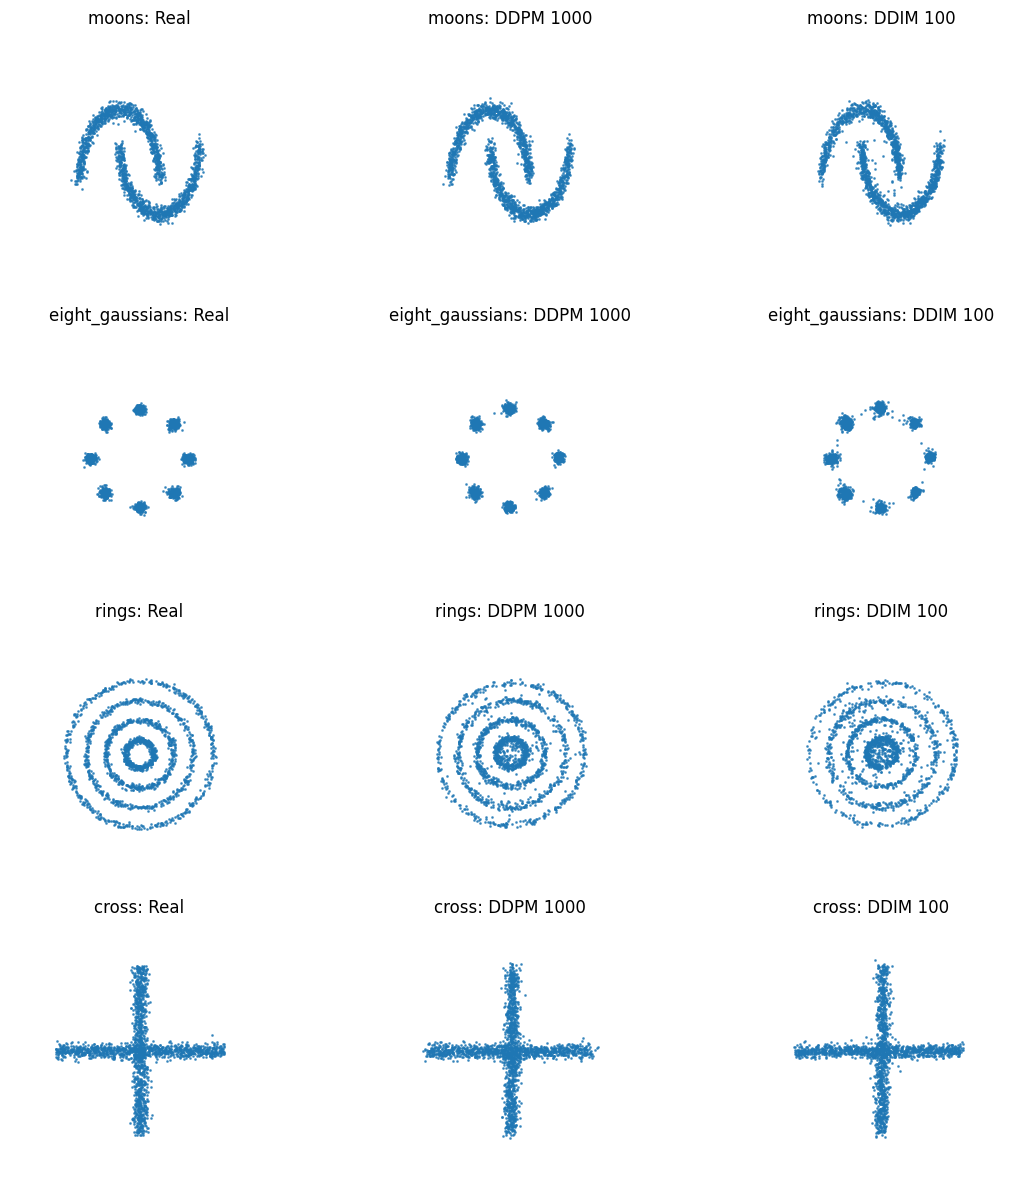

In [21]:
# DATASETS = ['swiss_roll','moons','circles','eight_gaussians','four_gaussians',
#             'two_gaussians','rings','spirals','checkerboard','pinwheel','grid','line',
#             'blobs','s_curve','cross','diamond','uniform_square','uniform_disk','star','heart']

TRAIN_DATASETS = ['moons', 'eight_gaussians', 'rings', 'cross']  # 또는 DATASETS (20종)
STEPS_PER_DATASET = 20000
previous_model, previous_X = model, X
fig, axs = plt.subplots(len(TRAIN_DATASETS), 3, figsize=(12, 3*len(TRAIN_DATASETS)), squeeze=False)
for row, name in enumerate(TRAIN_DATASETS):
    X = torch.tensor(toy_data(name, 10000), device=device)
    model = NoisePredictor().to(device)
    optim = torch.optim.Adam(model.parameters(), lr=2e-4)
    model.train()
    for step in range(STEPS_PER_DATASET):
        x0 = X[torch.randint(len(X), (512,), device=device)]
        ts = torch.randint(0, T, (len(x0),), device=device)
        noise = torch.randn_like(x0)
        loss = F.mse_loss(model(q_sample(x0, ts, noise), ts), noise)
        optim.zero_grad(); loss.backward(); optim.step()
    model.eval()
    original = X[:2000].cpu().numpy()
    ddpm,_ = sample_2d('ddpm', n=2000, keep=False)
    ddim,_ = sample_2d('ddim', steps=100, n=2000, keep=False)
    for col,(arr,label) in enumerate([(original, 'Real'), (ddpm.numpy(), 'DDPM 1000'), (ddim.numpy(), 'DDIM 100')]):
        ax=axs[row,col];ax.scatter(arr[:,0],arr[:,1],s=1,alpha=.7)
        ax.set(title=f'{name}: {label}', xlim=(-6,6),ylim=(-6,6),aspect='equal');ax.axis('off')
    print(f'{name}: trained {STEPS_PER_DATASET} steps')
model, X = previous_model, previous_X
plt.tight_layout();plt.show()


## G. Pretrained Diffusion Model for Image Generation

Extend the experiments from 2D toy datasets to image generation using a pretrained diffusion model.

### Load the Pretrained Model

Load a DDPM image generation model pretrained on CelebA-HQ at 256×256 resolution. Configure DDPM and DDIM schedulers to use the same U-Net noise prediction network.


In [ ]:
# 또는 'google/ddpm-church-256', 'google/ddpm-cat-256'
from diffusers import DDPMPipeline, DDPMScheduler, DDIMScheduler
from PIL import Image

MODEL_ID='google/ddpm-celebahq-256'
assert torch.cuda.is_available(), '256px image demo: Please using Colab GPU T4'
pipe=DDPMPipeline.from_pretrained(MODEL_ID, torch_dtype=torch.float16).to('cuda')
pipe.set_progress_bar_config(disable=True)
base_config=pipe.scheduler.config
scheduler_ddpm=DDPMScheduler.from_config(base_config)
scheduler_ddim=DDIMScheduler.from_config(base_config)
print(MODEL_ID, 'resolution:',pipe.unet.config.sample_size)


## H. Image Generation and Visualization

Define functions for generating and visualizing images using DDPM and DDIM.

### Image Generation Functions

Implement image generation functions with configurable sampling methods, inference steps, and random seeds. Generate images in small batches to reduce GPU memory usage and display the results in a grid.


In [ ]:
def image_grid(images,cols=4,title=''):
    rows=math.ceil(len(images)/cols)
    fig,axs=plt.subplots(rows,cols,figsize=(cols*2.4,rows*2.4),squeeze=False)
    for a in axs.flat: a.axis('off')
    for a,img in zip(axs.flat,images):a.imshow(img)
    fig.suptitle(title,fontsize=13);plt.tight_layout();plt.show()

@torch.inference_mode()
def generate_images(method,steps,n=8,batch=1,seed=42):
    # 같은 seed의 이미지별 초기 noise를 공유, DDPM은 추가 noise를 사용하므로 경로는 다름
    pipe.scheduler = (DDPMScheduler if method=='ddpm' else DDIMScheduler).from_config(base_config)
    g=torch.Generator(device='cuda').manual_seed(seed)
    shape=(n,pipe.unet.config.in_channels,pipe.unet.config.sample_size,pipe.unet.config.sample_size)
    initial=torch.randn(shape,generator=g,device='cuda',dtype=pipe.unet.dtype)
    images=[];torch.cuda.synchronize();tic=time.perf_counter()
    pipe.scheduler.set_timesteps(steps,device='cuda')
    for start in range(0,n,batch):
        x=initial[start:start+batch].clone()
        for t in pipe.scheduler.timesteps:
            eps=pipe.unet(x,t).sample
            x=pipe.scheduler.step(eps,t,x,generator=g).prev_sample
        # images normalized to [-1,1] by pipeline convention
        arr=((x/2+0.5).clamp(0,1).permute(0,2,3,1).float().cpu().numpy()*255).round().astype('uint8')
        images.extend([Image.fromarray(im) for im in arr])
    torch.cuda.synchronize()
    return images,time.perf_counter()-tic

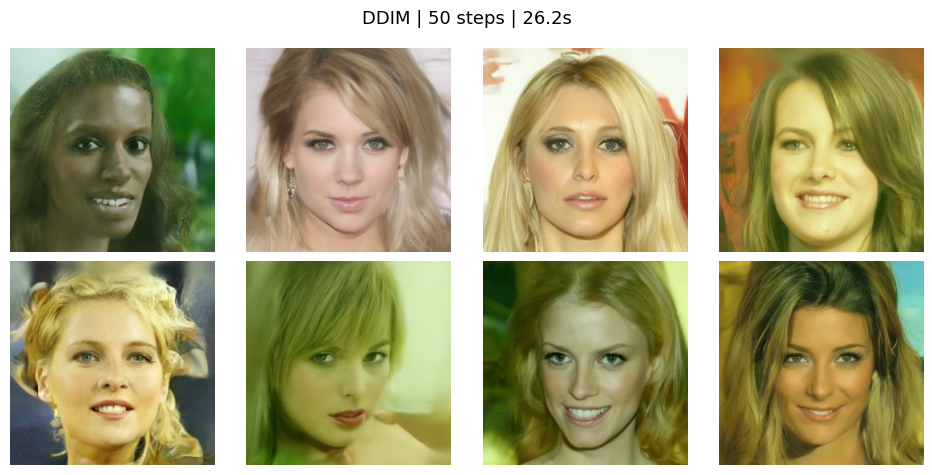

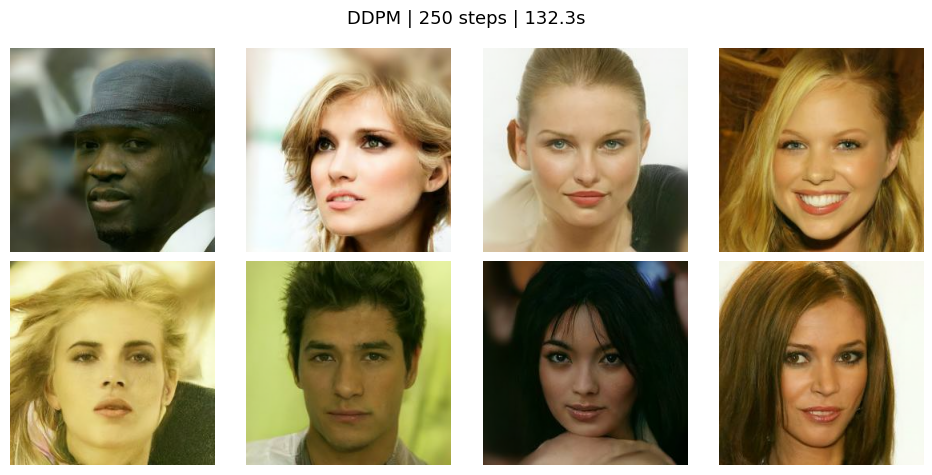

In [5]:
N_IMAGES=8
for method,steps in [('ddim',50),('ddpm',250)]:
    imgs,sec=generate_images(method,steps,n=N_IMAGES,batch=1,seed=42)
    image_grid(imgs,cols=4,title=f'{method.upper()} | {steps} steps | {sec:.1f}s')

In [ ]:
@torch.inference_mode()
def show_denoising_process(method='ddim', steps=50, seed=42, n_frames=8):
    pipe.scheduler = (DDPMScheduler if method == 'ddpm' else DDIMScheduler).from_config(base_config)

    g = torch.Generator(device='cuda').manual_seed(seed)

    shape = (
        1,
        pipe.unet.config.in_channels,
        pipe.unet.config.sample_size,
        pipe.unet.config.sample_size
    )

    x = torch.randn(shape, generator=g, device='cuda', dtype=pipe.unet.dtype)

    pipe.scheduler.set_timesteps(steps, device='cuda')
    timesteps = pipe.scheduler.timesteps

    # 보여줄 프레임 위치 선택
    frame_ids = np.linspace(0, len(timesteps) - 1, n_frames, dtype=int)
    frame_ids = sorted(set(frame_ids.tolist()))

    frames = []
    titles = []

    # 초기 noise도 먼저 저장
    arr = ((x / 2 + 0.5).clamp(0, 1).permute(0, 2, 3, 1).float().cpu().numpy()[0] * 255).round().astype('uint8')
    frames.append(arr)
    titles.append("start\n(noise)")

    for i, t in enumerate(timesteps):
        eps = pipe.unet(x, t).sample
        x = pipe.scheduler.step(eps, t, x, generator=g).prev_sample

        if i in frame_ids:
            arr = ((x / 2 + 0.5).clamp(0, 1).permute(0, 2, 3, 1).float().cpu().numpy()[0] * 255).round().astype('uint8')
            frames.append(arr)
            titles.append(f"step {i+1}\n(t={int(t)})")

    fig, axes = plt.subplots(1, len(frames), figsize=(2.6 * len(frames), 3))
    if len(frames) == 1:
        axes = [axes]

    for ax, img, title in zip(axes, frames, titles):
        ax.imshow(img)
        ax.set_title(title, fontsize=10)
        ax.axis('off')

    fig.suptitle(f"{method.upper()} Denoising Process | {steps} steps", fontsize=14)
    plt.tight_layout()
    plt.show()

In [ ]:
show_denoising_process(method='ddpm', steps=250, seed=42, n_frames=8)


## I. DDPM vs DDIM: Sampling Steps Comparison

Compare the image generation quality and execution time of DDPM and DDIM using the same pretrained model.

### Sampling Steps Comparison

Generate images from the same initial Gaussian noise using 5, 10, 25, 50, and 100 sampling steps. Compare the generated images and execution times to examine how the number of denoising steps affects image quality and sampling efficiency.


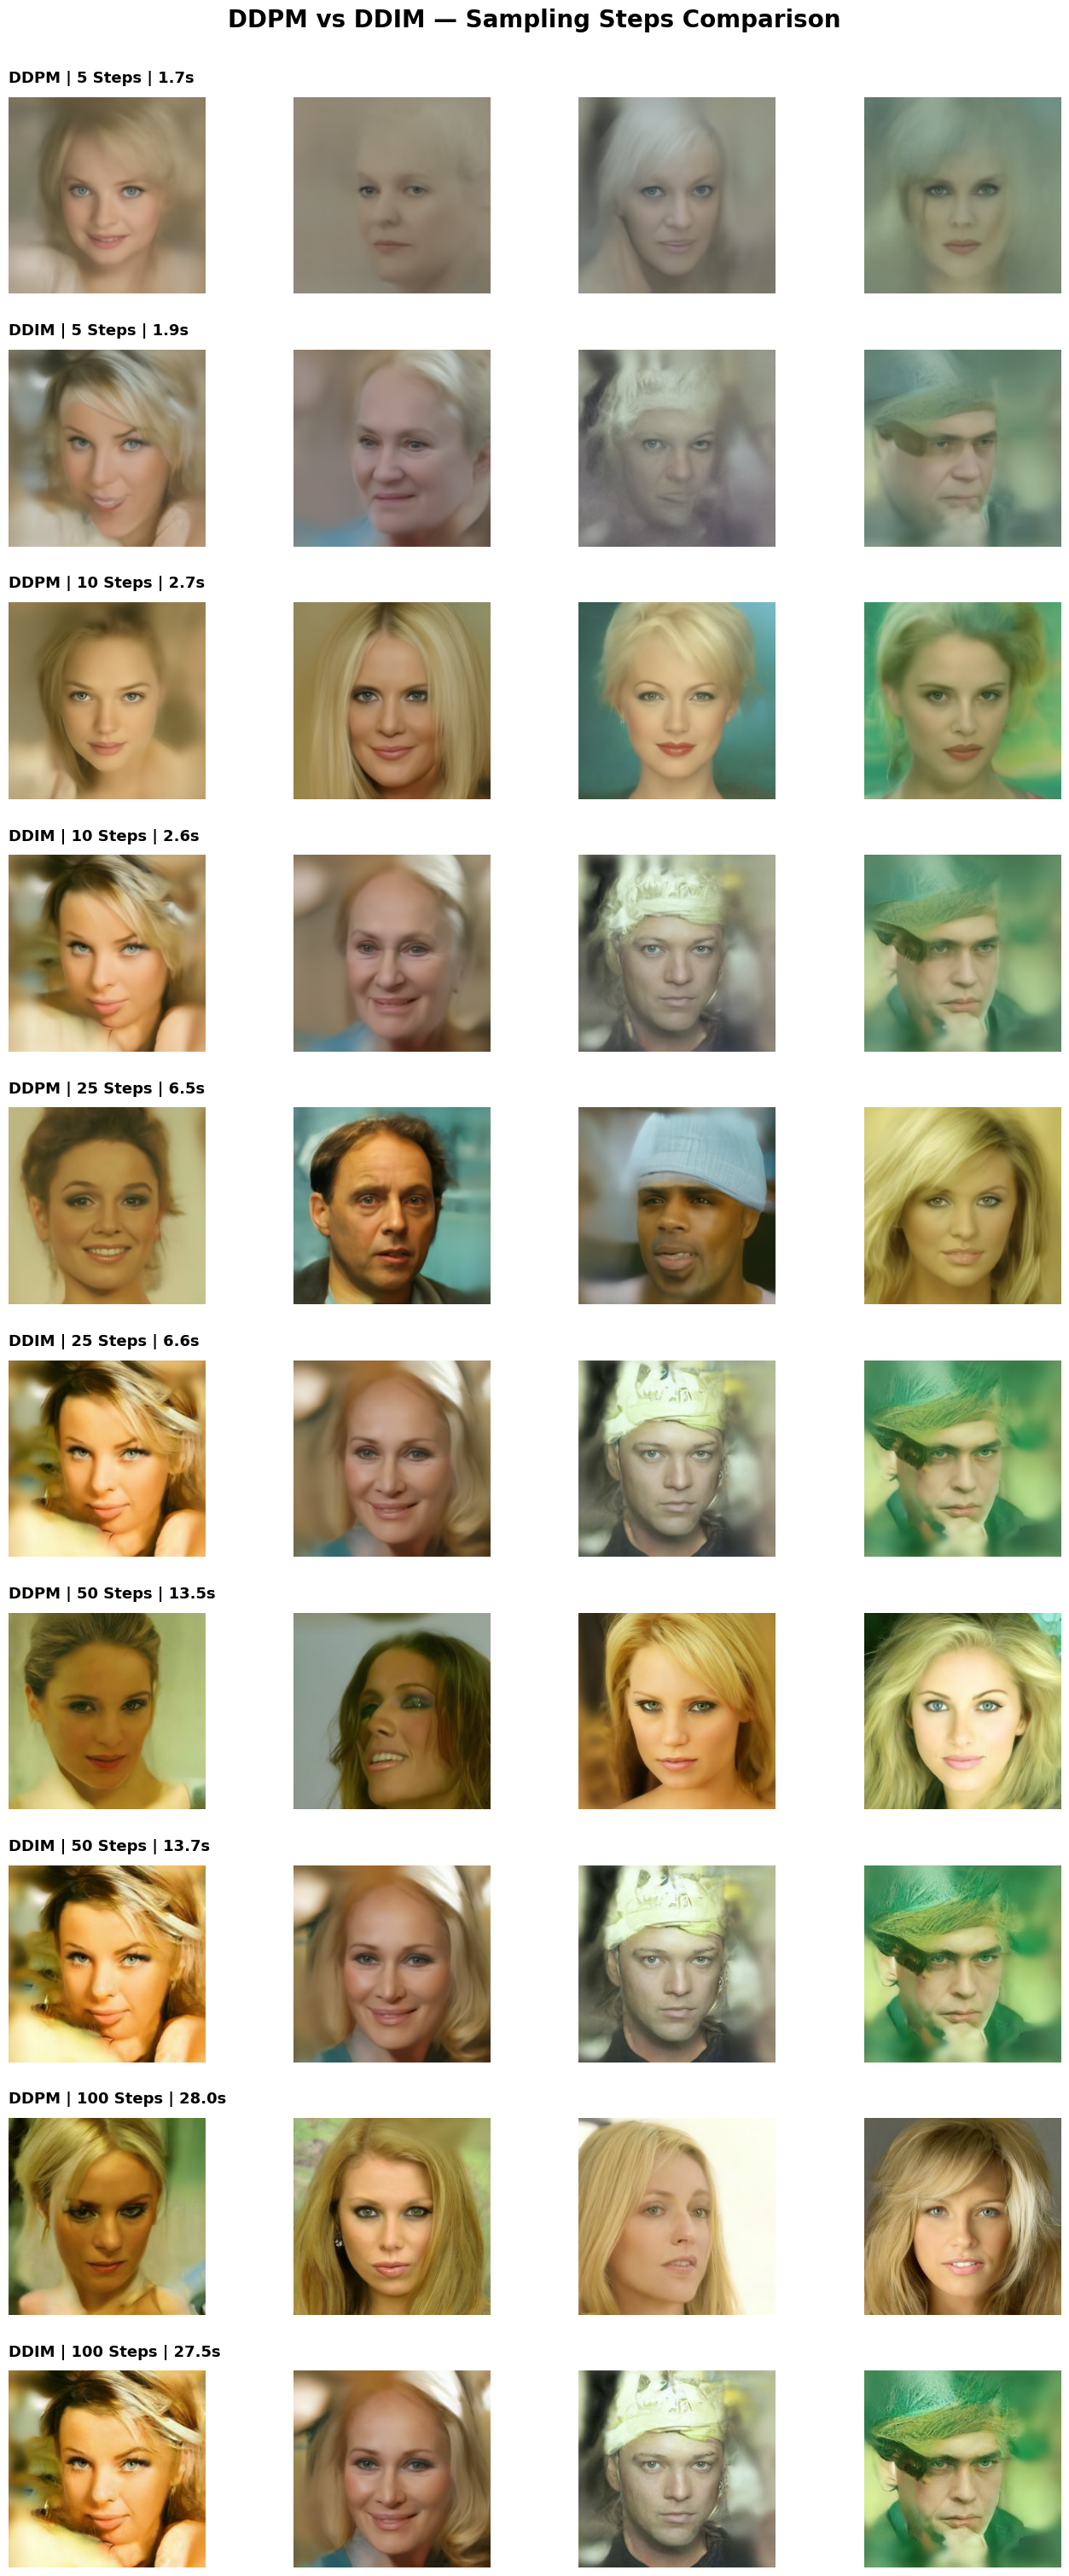

In [7]:
steps_list = [5, 10, 25, 50, 100]
seed = 17
n_samples = 4

fig, axes = plt.subplots(
    len(steps_list) * 2, n_samples,
    figsize=(14, 3 * len(steps_list) * 2)
)

fig.suptitle(
    "DDPM vs DDIM — Sampling Steps Comparison",
    fontsize=20, fontweight="bold", y=1.005
)

for i, steps in enumerate(steps_list):
    for j, method in enumerate(["ddpm", "ddim"]):
        images, elapsed = generate_images(
            method, steps,
            n=n_samples, batch=1, seed=seed
        )

        row = i * 2 + j

        for col, img in enumerate(images):
            axes[row, col].imshow(img)
            axes[row, col].axis("off")

        # 각 행의 제목
        axes[row, 0].set_title(
            f"{method.upper()} | {steps} Steps | {elapsed:.1f}s",
            fontsize=13, fontweight="bold",
            loc="left", pad=12
        )

plt.tight_layout(h_pad=2.5, w_pad=0.5)
plt.show()

**References:** [KAIST CS492(C) 2025 Assignment 1](https://github.com/KAIST-Visual-AI-Group/Diffusion-2025-Assignment1-DDPM-DDIM) · [CelebA-HQ pretrained DDPM](https://huggingface.co/google/ddpm-celebahq-256) · [Diffusers schedulers](https://huggingface.co/docs/diffusers/api/schedulers/overview)